# TP : Latent Semantic Analysis (LSA)
## Text Mining

### Objectif
Dans ce TP, nous allons :
1. Construire une matrice Documents × Termes
2. Calculer la matrice TF‑IDF
3. Calculer la similarité cosinus entre documents
4. Appliquer la décomposition SVD (LSA)
5. Réduire la dimension (k = 2)
6. Comparer la similarité **avant et après LSA**
7. Visualiser les documents dans l’espace latent


## Corpus (6 documents)

**Doc1** : La programmation Python est très utilisée en science des données.

**Doc2** : Le basket-ball et le volleyball sont des sports collectifs populaires.

**Doc3** : Les algorithmes d'apprentissage automatique traitent de grandes données.

**Doc4** : La natation et la course à pied améliorent la condition physique.

**Doc5** : Python et R sont des langages de programmation pour la statistique.

**Doc6** : Les sports d'équipe favorisent la coopération entre les joueurs.


#  Instructions
Complétez chaque cellule marquée  # ...

Répondez aux questions dans les cellules Markdown prévues à cet effet

Exécutez les cellules dans l'ordre

## Étape 1 : Prétraitement et Vocabulaire

In [1]:
terms = ["programmation", "Python", "utilisée", "science", "données",
         "basket-ball", "volleyball", "sports", "collectifs", "populaires",
         "algorithmes", "apprentissage", "automatique", "traitent", "grandes",
         "natation", "course", "pied", "améliorent", "condition", "physique",
         "R"," langages","statistique",
         "sports", "équipe", " favorisent", "cooperatif", "joueurs"
]

terms

terms

['programmation',
 'Python',
 'utilisée',
 'science',
 'données',
 'basket-ball',
 'volleyball',
 'sports',
 'collectifs',
 'populaires',
 'algorithmes',
 'apprentissage',
 'automatique',
 'traitent',
 'grandes',
 'natation',
 'course',
 'pied',
 'améliorent',
 'condition',
 'physique',
 'R',
 ' langages',
 'statistique',
 'sports',
 'équipe',
 ' favorisent',
 'cooperatif',
 'joueurs']

## Étape 2 : Matrice Documents × Termes (fréquences)

In [8]:
import numpy as np

M = np.array([
    [1,    1,    1,    1,    1,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0],  # Doc1
    [0,    0,    0,    0,    0,    1,    1,    1,    1,    1,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    1,    0,    0,    0,    0],  # Doc2
    [0,    0,    0,    0,    1,    0,    0,    0,    0,    0,    1,    1,    1,    1,    1,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0],  # Doc3
    [0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    1,    1,    1,    1,    1,    1,    0,    0,    0,    0,    0,    0,    0,    0],  # Doc4
    [1,    1,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    1,    1,    1,    0,    0,    0,    0,    0],  # Doc5
    [0,    0,    0,    0,    0,    0,    0,    1,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    1,    1,    1,    0,    1],  # Doc6
])
print("Matrice Documents × Termes M = \n", M)

Matrice Documents × Termes M = 
 [[1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 0 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 1]]


## Étape 3 : Calcul de la matrice TF‑IDF

In [5]:
from sklearn.feature_extraction.text import TfidfTransformer

tfidf = TfidfTransformer()
A = tfidf.fit_transform(M).toarray()

print("La matrice TF‑IDF A = ", A)

La matrice TF‑IDF A =  [[0.40912489 0.40912489 0.49892408 0.49892408 0.40912489 0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.43254606
  0.43254606 0.35469396 0.43254606 0.43254606 0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.35469396 0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.34430007 0.
  0.         0.         0.         0.         0.4198708  0.4198708
  0.4198708  0.4198708  0.4198708  0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.    

## Étape 4 : Similarité cosinus avant LSA

In [9]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_before = cosine_similarity(A)

print("La matrice de similarité cosinus avant LSA est \n", similarity_before)

La matrice de similarité cosinus avant LSA est 
 [[1.         0.         0.14086173 0.         0.32189934 0.        ]
 [0.         1.         0.         0.         0.         0.2790731 ]
 [0.14086173 0.         1.         0.         0.         0.        ]
 [0.         0.         0.         1.         0.         0.        ]
 [0.32189934 0.         0.         0.         1.         0.        ]
 [0.         0.2790731  0.         0.         0.         1.        ]]


### Questions

1. Quelle est la similarité entre Doc1 et Doc3 ? 0.14 : Tres faible similarite
2. Quelle est la similarité entre Doc2 et Doc4 ? 0 : Aucune ressemblance
3. Quelle est la similarité entre Doc1 et Doc2 ? 0 : Aucune ressemblance
4. Quels documents semblent appartenir au même thème ? 
0.32 : Doc 5 et Doc 1
0.27 : Doc 6 et Doc 2
0.14 : Doc 3 et Doc 1

## Étape 5 : Décomposition SVD (LSA)
Consigne : Calculez la SVD complète de M avec numpy.linalg.svd

In [ ]:
U, S, VT = np.linalg.svd(A, full_matrices=False)
#np.linalg.svd : c'est une fonction de numpy qui fait la décomposition SVD.

# Plus le score est grand -> plus le document appartient à ce thème
# Les petits chiffres comme 1.02e-16 = 0. C'est juste Python qui écrit des zéros imparfaits. Lis-les comme 0
print('U =')
print(U)

# le plus important 
# Ce sont les poids de chaque thème (l'importance de chaque theme), du plus important au moins important 
print('\nValeurs singulières =')
print(S)

# Plus le score est grand -> plus le mot appartient à ce thème
print('\nV^T =')
print(VT)

U =
[[-7.07106781e-01  1.02003856e-16  5.03893150e-17 -8.09809429e-32
  -1.16601301e-16  7.07106781e-01]
 [ 0.00000000e+00 -7.07106781e-01  3.88578059e-16  4.68785282e-16
   7.07106781e-01  0.00000000e+00]
 [-2.83473681e-01 -8.47092152e-17  9.16125179e-01 -2.87686984e-16
  -6.18067908e-17 -2.83473681e-01]
 [ 0.00000000e+00 -3.33066907e-16 -3.88578059e-16 -1.00000000e+00
   4.44089210e-16  0.00000000e+00]
 [-6.47798327e-01 -2.79812847e-16 -4.00892325e-01  1.25890551e-16
   3.89275460e-16 -6.47798327e-01]
 [ 0.00000000e+00 -7.07106781e-01 -3.19154503e-16 -3.92459808e-16
  -7.07106781e-01  0.00000000e+00]]

Valeurs singulières =
[1.16248461 1.13096114 1.         1.         0.84907414 0.8053754 ]

V^T =
[[-4.68082536e-01 -4.68082536e-01 -3.03481525e-01 -3.03481525e-01
  -3.32817299e-01 -4.10524400e-18 -4.10524400e-18 -1.13463312e-17
  -4.10524400e-18 -4.10524400e-18 -1.02386149e-01 -1.02386149e-01
  -1.02386149e-01 -1.02386149e-01 -1.02386149e-01  6.32414929e-18
   6.32414929e-18  6.324149

### Vérification : reconstruction de M à partir de U·Σ·Vᵀ
#### But : S'assurer que la décomposition est correcte

In [ ]:
# On a deconstruit la matrice A en trois matrices U, S et VT. On peut les multiplier pour reconstruire la matrice M
# @ : Symbole de la multiplication de matrice
M_reconstruit = U * S @ VT

# np.round(..., 2) : arrondit à 2 décimales pour que ce soit lisible
print("Matrice reconstruite =\n", np.round(M_reconstruit, 2))
print("\nMatrice originale M =\n", np.round(M, 2))

Matrice reconstruite =
 [[ 0.41  0.41  0.5   0.5   0.41 -0.   -0.   -0.   -0.   -0.   -0.   -0.
  -0.   -0.   -0.    0.    0.    0.    0.    0.    0.   -0.   -0.   -0.
  -0.    0.    0.    0.    0.  ]
 [ 0.    0.   -0.   -0.   -0.    0.43  0.43  0.35  0.43  0.43 -0.   -0.
  -0.   -0.   -0.   -0.   -0.   -0.   -0.   -0.   -0.    0.    0.    0.
   0.35  0.    0.    0.    0.  ]
 [-0.   -0.    0.   -0.    0.34  0.    0.    0.    0.    0.    0.42  0.42
   0.42  0.42  0.42 -0.   -0.   -0.   -0.   -0.   -0.   -0.   -0.   -0.
   0.   -0.   -0.    0.   -0.  ]
 [ 0.    0.   -0.   -0.   -0.    0.    0.    0.    0.    0.   -0.   -0.
  -0.   -0.   -0.    0.41  0.41  0.41  0.41  0.41  0.41  0.    0.    0.
   0.    0.    0.    0.    0.  ]
 [ 0.39  0.39  0.    0.   -0.    0.    0.    0.    0.    0.   -0.   -0.
  -0.   -0.   -0.    0.    0.    0.    0.    0.    0.    0.48  0.48  0.48
   0.    0.    0.    0.    0.  ]
 [ 0.    0.   -0.   -0.   -0.    0.    0.    0.39  0.    0.   -0.   -0.
  -0.   -0.   -

## Étape 6 : Réduction dimensionnelle (k = 2)
#### k=2 : On garde les 2 themes les plus importants parmi les 6
#### On sait qu'il y a 6 themes grace aux valeurs singulières S : [1.16,  1.13,  1.0,  1.0,  0.85,  0.81] -> Les 2 premières valeurs sont les plus grandes, donc k=2

In [ ]:
k = 2

# On garde les 2 premières colonnes de U, les 2 thèmes pour les docs
U_k = U[:, :k]
# On garde les 2 premières valeurs de S, les 2 thèmes les plus importants
Sigma_k = np.diag(S[:k])
# On garde les 2 premières lignes de VT, les 2 thèmes pour les mots
V_k = VT[:k, :]

print("U_k =\n", U_k)
# Le but
print("\nSigma_k =\n", Sigma_k)


U_k =
 [[-7.07106781e-01  1.02003856e-16]
 [ 0.00000000e+00 -7.07106781e-01]
 [-2.83473681e-01 -8.47092152e-17]
 [ 0.00000000e+00 -3.33066907e-16]
 [-6.47798327e-01 -2.79812847e-16]
 [ 0.00000000e+00 -7.07106781e-01]]

Sigma_k =
 [[1.16248461 0.        ]
 [0.         1.13096114]]


## Étape 7 : Coordonnées des documents dans l’espace latent

In [18]:
# T_k = la nouvelle position des documents dans les thèmes (car on a reduit a k=)
T_k = U_k @ Sigma_k

print("\nT_k =\n", T_k)



T_k =
 [[-8.22000752e-01  1.15362397e-16]
 [ 0.00000000e+00 -7.99710291e-01]
 [-3.29533792e-01 -9.58028306e-17]
 [ 0.00000000e+00 -3.76685729e-16]
 [-7.53055586e-01 -3.16457457e-16]
 [ 0.00000000e+00 -7.99710291e-01]]


## Étape 8 : Similarité cosinus APRÈS LSA
#### But : Comparer les documents avec leurs nouvelles coordonnées T_k

In [19]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_after = cosine_similarity(T_k)

print(np.round(similarity_after, 2))

[[ 1. -0.  1. -0.  1. -0.]
 [-0.  1.  0.  0.  0.  1.]
 [ 1.  0.  1.  0.  1.  0.]
 [-0.  0.  0.  0.  0.  0.]
 [ 1.  0.  1.  0.  1.  0.]
 [-0.  1.  0.  0.  0.  1.]]


### Questions

1. La similarité entre Doc1 et Doc3 a‑t‑elle augmenté ? Oui, similarité = 1.0 (contre 0.14 avant)
2. La similarité entre Doc2 et Doc4 a‑t‑elle augmenté ? Non (reste 0)
3. Les documents Art et Programmation sont‑ils mieux séparés ? Oui 

## Étape 9 : Visualisation des documents

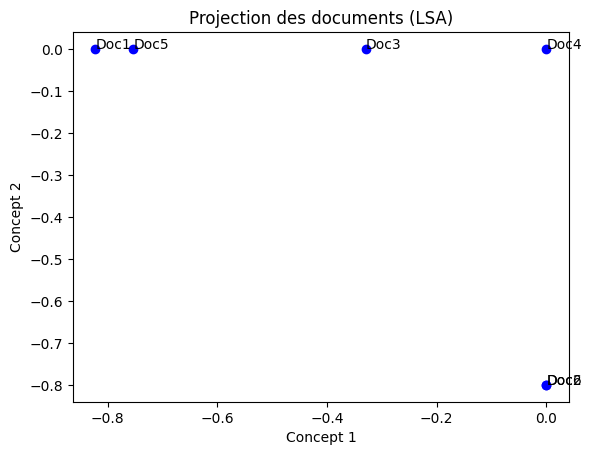

In [20]:
import matplotlib.pyplot as plt

docs = ['Doc1','Doc2','Doc3','Doc4','Doc5','Doc6']

plt.figure()
plt.scatter(T_k[:, 0], T_k[:, 1], color='blue')

for i, doc in enumerate(docs):
    plt.annotate(doc, (T_k[i, 0], T_k[i, 1]))


plt.xlabel('Concept 1')
plt.ylabel('Concept 2')
plt.title('Projection des documents (LSA)')
plt.show()